# Heston model — Monte Carlo simulation

This notebook implements and compares two simulation schemes for the Heston model:

- the **full truncation Euler** scheme;
- Andersen's (2008) **Quadratic-Exponential** (QE) scheme.

The reference price is given by the **Lewis formula**, validated in the previous part.

The notebook has two parts.

**Part I — Standard Monte Carlo**

1. **Law of the variance over one step**: comparison of the two schemes with the exact CIR law (noncentral chi-squared).
2. **Discretisation bias** as a function of the number of steps, when the Feller condition is satisfied and then violated.
3. **Statistical error** as a function of the number of paths.
4. **Computation time**.
5. **Cross-check on a full smile**: Monte Carlo versus Lewis.

**Part II — Variance reduction**

6. Three methods compared with standard Monte Carlo, at the money: conditional, control variate, conditional + control variate.
7. Variance gain over the whole strike range, and check that there is no bias.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.stats import norm, wasserstein_distance

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## 1. Reference pricer: Lewis formula

We reuse the functions of the previous part, unchanged.

In [2]:
def heston_char(u, S0, T, r, kappa, theta, xi, rho, v0):
    b = kappa - 1j * rho * xi * u
    d = np.sqrt(b**2 + xi**2 * (u**2 + 1j * u))
    g = (b - d) / (b + d)

    D = (b - d) / xi**2 * (1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T))
    C = 1j * u * r * T + kappa * theta / xi**2 * (
        (b - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g))
    )
    return np.exp(C + D * v0 + 1j * u * np.log(S0))


def lewis_call_price(S0, K, T, r, kappa, theta, xi, rho, v0, u_max=200.0):
    p = (S0, T, r, kappa, theta, xi, rho, v0)
    k = np.log(K)

    def integrand(u):
        return (np.exp(-1j * u * k) * heston_char(u - 0.5j, *p)).real / (u**2 + 0.25)

    integral = quad(integrand, 0.0, u_max, limit=500, epsabs=1e-12, epsrel=1e-12)[0]
    return S0 - np.sqrt(K) * np.exp(-r * T) / np.pi * integral


def bs_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def implied_vol(price, S0, K, T, r):
    return brentq(lambda s: bs_call(S0, K, T, r, s) - price, 1e-6, 5.0, xtol=1e-12)

## 2. Parameters

We reuse the two parameter sets of the project: one satisfies the Feller condition, the other clearly violates it, like the parameters obtained by calibration on AAPL.

In [3]:
S0, K, T, r = 100.0, 100.0, 1.0, 0.03

cases = {
    "Feller satisfied": dict(kappa=3.0, theta=0.04, xi=0.3, rho=-0.6, v0=0.04),
    "Feller violated": dict(kappa=1.0, theta=0.04, xi=1.2, rho=-0.7, v0=0.04),
}

for name, p in cases.items():
    feller = 2 * p["kappa"] * p["theta"] - p["xi"]**2
    d_dim = 4 * p["kappa"] * p["theta"] / p["xi"]**2
    price_ref = lewis_call_price(S0, K, T, r, **p)
    print(f"{name:16s}  2*kappa*theta - xi^2 = {feller:+.3f}   d = {d_dim:.3f}   Lewis price = {price_ref:.6f}")

Feller satisfied  2*kappa*theta - xi^2 = +0.150   d = 5.333   Lewis price = 9.308051
Feller violated   2*kappa*theta - xi^2 = -1.360   d = 0.111   Lewis price = 7.022250


## 3. Exact CIR law and conditional moments

For a step $\Delta$, conditionally on $v_t$:

$$
m = \mathbb E[v_{t+\Delta} \mid v_t] = \theta + (v_t - \theta)e^{-\kappa\Delta},\qquad
s^2 = \mathrm{Var}(v_{t+\Delta} \mid v_t) = \frac{v_t\xi^2 e^{-\kappa\Delta}}{\kappa}(1-e^{-\kappa\Delta}) + \frac{\theta\xi^2}{2\kappa}(1-e^{-\kappa\Delta})^2,
$$

and the exact law is $v_{t+\Delta} \overset{d}{=} c\,\chi'^2_d(\lambda)$, with
$c = \frac{\xi^2(1-e^{-\kappa\Delta})}{4\kappa}$, $d = \frac{4\kappa\theta}{\xi^2}$, $\lambda = \frac{v_t e^{-\kappa\Delta}}{c}$.

In [4]:
def cir_moments(v, dt, kappa, theta, xi):
    e = np.exp(-kappa * dt)
    m = theta + (v - theta) * e
    s2 = v * xi**2 * e / kappa * (1 - e) + theta * xi**2 / (2 * kappa) * (1 - e)**2
    return m, s2


def cir_exact_step(v, dt, kappa, theta, xi, rng):
    e = np.exp(-kappa * dt)
    c = xi**2 * (1 - e) / (4 * kappa)
    d = 4 * kappa * theta / xi**2
    lam = v * e / c
    return c * rng.noncentral_chisquare(d, lam, size=np.shape(v))

## 4. Full truncation Euler scheme

We replace $v_t$ by $v_t^+ = \max(v_t, 0)$ in the drift and in the diffusion, without truncating the state itself. The log-price is discretised by Euler on $X_t = \ln S_t$:

$$
v_{t+\Delta} = v_t + \kappa(\theta - v_t^+)\Delta + \xi\sqrt{v_t^+\Delta}\,Z_v,\qquad
X_{t+\Delta} = X_t + (r - \tfrac12 v_t^+)\Delta + \sqrt{v_t^+\Delta}\,Z_S,
$$

with $Z_S = \rho Z_v + \sqrt{1-\rho^2}\,Z_\perp$.

In [5]:
def heston_paths_euler(S0, r, T, kappa, theta, xi, rho, v0, n_steps, n_paths, seed=0):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    v = np.full(n_paths, v0)
    X = np.full(n_paths, np.log(S0))
    n_neg = 0

    for _ in range(n_steps):
        v_pos = np.maximum(v, 0.0)
        n_neg += np.count_nonzero(v < 0)
        Zv = rng.standard_normal(n_paths)
        Zs = rho * Zv + np.sqrt(1 - rho**2) * rng.standard_normal(n_paths)

        X = X + (r - 0.5 * v_pos) * dt + np.sqrt(v_pos * dt) * Zs
        v = v + kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos * dt) * Zv

    frac_neg = n_neg / (n_steps * n_paths)
    return np.exp(X), np.maximum(v, 0.0), frac_neg

## 5. Andersen's QE scheme

**Variance.** We compute $m$, $s^2$ and $\psi = s^2/m^2$, then:

- if $\psi \le \psi_c$ (quadratic branch): $v_{t+\Delta} = a(b + Z_v)^2$, with
  $b^2 = \frac2\psi - 1 + \sqrt{\frac2\psi}\sqrt{\frac2\psi - 1}$ and $a = \frac{m}{1+b^2}$;
- if $\psi > \psi_c$ (exponential branch): $p = \frac{\psi - 1}{\psi + 1}$, $\beta = \frac{1-p}{m}$, and
  $v_{t+\Delta} = 0$ if $U \le p$, $v_{t+\Delta} = \beta^{-1}\ln\frac{1-p}{1-U}$ otherwise.

**Log-price.** Andersen's scheme, where the integral of the variance is approximated by the trapezoidal rule ($\gamma_1 = \gamma_2 = \tfrac{1}{2}$): $\int_t^{t+\Delta} v_s\,ds \approx (\gamma_1 v_t + \gamma_2 v_{t+\Delta})\Delta$:

$$
X_{t+\Delta} = X_t + r\Delta + K_0 + K_1 v_t + K_2 v_{t+\Delta} + \sqrt{K_3 v_t + K_4 v_{t+\Delta}}\;Z_S,
$$
$$
K_0 = -\frac{\rho\kappa\theta}{\xi}\Delta,\quad
K_1 = \gamma_1\Delta\Big(\frac{\kappa\rho}{\xi} - \frac12\Big) - \frac\rho\xi,\quad
K_2 = \gamma_2\Delta\Big(\frac{\kappa\rho}{\xi} - \frac12\Big) + \frac\rho\xi,\quad
K_3 = \gamma_1\Delta(1-\rho^2),\quad K_4 = \gamma_2\Delta(1-\rho^2).
$$

The sampling is fully vectorised: we draw $Z_v$ and $U$ for all paths, then choose the branch with `np.where`.

In [6]:
def qe_variance_from_draws(v, dt, kappa, theta, xi, Zv, U, psi_c=1.5):

    m, s2 = cir_moments(v, dt, kappa, theta, xi)
    psi = s2 / m**2

    # Quadratic branch (psi <= psi_c)
    psi_q = np.minimum(psi, psi_c)
    inv = 2.0 / psi_q
    b2 = inv - 1.0 + np.sqrt(inv) * np.sqrt(inv - 1.0)
    a = m / (1.0 + b2)
    v_quad = a * (np.sqrt(b2) + Zv)**2

    # Exponential branch (psi > psi_c)
    psi_e = np.maximum(psi, psi_c)
    p = (psi_e - 1.0) / (psi_e + 1.0)
    beta = (1.0 - p) / m
    v_exp = np.where(U <= p, 0.0, np.log((1.0 - p) / np.maximum(1.0 - U, 1e-300)) / beta)

    return np.where(psi <= psi_c, v_quad, v_exp)


def qe_variance_step(v, dt, kappa, theta, xi, rng, psi_c=1.5):
    n = v.shape[0]
    Zv = rng.standard_normal(n)
    U = rng.random(n)
    return qe_variance_from_draws(v, dt, kappa, theta, xi, Zv, U, psi_c)


def heston_paths_qe(S0, r, T, kappa, theta, xi, rho, v0, n_steps, n_paths, seed=0,psi_c=1.5, gamma1=0.5, gamma2=0.5):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    K0 = -rho * kappa * theta / xi * dt
    K1 = gamma1 * dt * (kappa * rho / xi - 0.5) - rho / xi
    K2 = gamma2 * dt * (kappa * rho / xi - 0.5) + rho / xi
    K3 = gamma1 * dt * (1 - rho**2)
    K4 = gamma2 * dt * (1 - rho**2)

    v = np.full(n_paths, v0)
    X = np.full(n_paths, np.log(S0))
    for _ in range(n_steps):
        v_next = qe_variance_step(v, dt, kappa, theta, xi, rng, psi_c)
        Zs = rng.standard_normal(n_paths)
        X = X + r * dt + K0 + K1 * v + K2 * v_next + np.sqrt(K3 * v + K4 * v_next) * Zs
        v = v_next
    return np.exp(X), v

## 6. Monte Carlo estimators

- `mc_call_price`: standard estimator, with its standard error $\hat\sigma/\sqrt N$. The Python loop of the previous version is replaced by a vectorised computation (same result, about 100 times faster).
- `martingale_correction`: empirical correction of Duan and Simonato, which forces $\overline{S_T} = S_0e^{rT}$. It is **not** used in the bias tests, since it would mask part of the bias of the schemes.

The variance reduction estimators are gathered in Part II.

In [7]:
def mc_call_price(S_T, K, T, r):
    N = len(S_T)
    Y = np.exp(-r * T) * np.maximum(S_T - K, 0.0)

    C_hat = np.sum(Y) / N
    sigma_hat = np.sqrt(np.sum((Y - C_hat) ** 2) / (N - 1))
    se = sigma_hat / np.sqrt(N)

    return C_hat, se


def martingale_correction(S_T, S0, r, T):
    N = len(S_T)
    S_bar = np.sum(S_T) / N
    return S_T * S0 * np.exp(r * T) / S_bar

# Part I — Standard Monte Carlo

## Test 1 — Law of the variance over one step

We simulate **a single step** of size $\Delta$ from $v_0$, and compare the resulting law with the exact law (noncentral chi-squared), in the case where Feller is violated. We measure the Wasserstein distance $W_1$ between each scheme and an exact sample (it directly controls the gap on the expectation of any 1-Lipschitz function, hence on prices), the mass close to $0$ and the standard deviation.

In [8]:
p = cases["Feller violated"]
n_test = 400_000
rows = []
samples = {}

for dt in [0.5, 0.1, 0.02]:
    rng = np.random.default_rng(1)
    v_start = np.full(n_test, p["v0"])
    v_exact = cir_exact_step(v_start, dt, p["kappa"], p["theta"], p["xi"], rng)
    v_qe = qe_variance_step(v_start, dt, p["kappa"], p["theta"], p["xi"], rng)
    Z = rng.standard_normal(n_test)
    v_eul = p["v0"] + p["kappa"] * (p["theta"] - p["v0"]) * dt + p["xi"] * np.sqrt(p["v0"] * dt) * Z
    samples[dt] = (v_exact, v_qe, v_eul)

    m, s2 = cir_moments(p["v0"], dt, p["kappa"], p["theta"], p["xi"])
    rows.append((dt, s2 / m**2,
                 wasserstein_distance(v_qe, v_exact), wasserstein_distance(np.maximum(v_eul, 0), v_exact),
                 np.mean(v_exact <= 1e-3), np.mean(v_qe <= 1e-3), np.mean(v_eul <= 1e-3),
                 np.std(v_exact), np.std(v_qe), np.std(np.maximum(v_eul, 0))))

print(f"{'dt':>5} | {'psi':>6} | {'W1 QE':>8} | {'W1 Euler':>8} | {'P(v<=1e-3) exact / QE / Euler':>30} | {'std dev exact / QE / Euler+':>31}")
for row in rows:
    print(f"{row[0]:5.2f} | {row[1]:6.3f} | {row[2]:8.5f} | {row[3]:8.5f} | "
          f"{row[4]:8.3f} / {row[5]:6.3f} / {row[6]:6.3f}       | {row[7]:8.4f} / {row[8]:6.4f} / {row[9]:6.4f}")

   dt |    psi |    W1 QE | W1 Euler |  P(v<=1e-3) exact / QE / Euler |     std dev exact / QE / Euler+
 0.50 | 11.378 |  0.00496 |  0.06461 |    0.691 /  0.840 /  0.408       |   0.1348 / 0.1349 / 0.1123
 0.10 |  3.263 |  0.00062 |  0.02340 |    0.483 /  0.538 /  0.303       |   0.0719 / 0.0723 / 0.0571
 0.02 |  0.706 |  0.00049 |  0.00530 |    0.067 /  0.038 /  0.125       |   0.0336 / 0.0337 / 0.0305


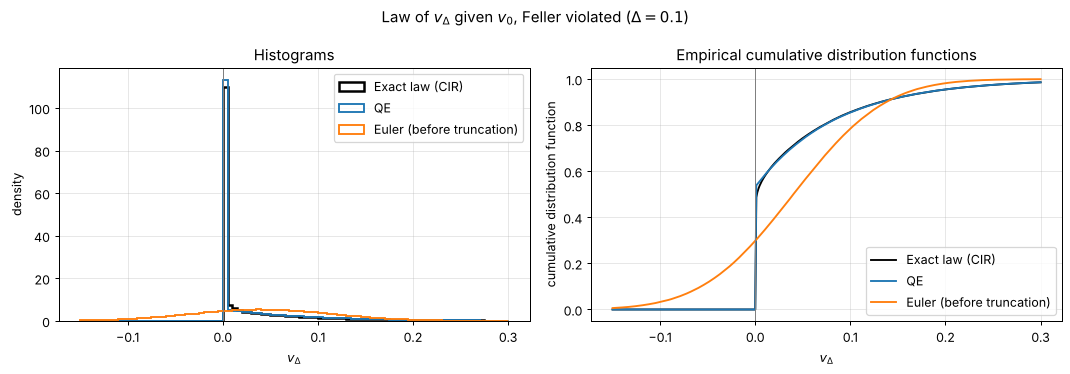

In [9]:
# FIG: loi_un_pas
dt_plot = 0.1
v_exact, v_qe, v_eul = samples[dt_plot]
grid = np.linspace(-0.15, 0.3, 400)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.linspace(-0.15, 0.3, 91)
ax[0].hist(v_exact, bins=bins, density=True, histtype="step", lw=2, color="k", label="Exact law (CIR)")
ax[0].hist(v_qe, bins=bins, density=True, histtype="step", lw=1.5, label="QE")
ax[0].hist(v_eul, bins=bins, density=True, histtype="step", lw=1.5, label="Euler (before truncation)")
ax[0].axvline(0, color="grey", lw=0.8)
ax[0].set_xlabel(r"$v_{\Delta}$"); ax[0].set_ylabel("density"); ax[0].set_title("Histograms")
ax[0].legend()

for data, lab, style in [(v_exact, "Exact law (CIR)", "k-"), (v_qe, "QE", "-"), (v_eul, "Euler (before truncation)", "-")]:
    ax[1].plot(grid, np.searchsorted(np.sort(data), grid) / len(data), style, lw=1.5, label=lab)
ax[1].axvline(0, color="grey", lw=0.8)
ax[1].set_xlabel(r"$v_{\Delta}$"); ax[1].set_ylabel("cumulative distribution function"); ax[1].set_title("Empirical cumulative distribution functions")
ax[1].legend()
fig.suptitle(rf"Law of $v_\Delta$ given $v_0$, Feller violated ($\Delta = {dt_plot}$)")
plt.tight_layout()
plt.show()

## Test 2 — Discretisation bias as a function of the number of steps

We use $N = 500\,000$ paths, **without martingale correction**, to measure the actual bias of the schemes. Each error is given in basis points of the reference price, with its 95% confidence interval: a gap smaller than this half-width is not significant.

In [10]:
n_paths = 500_000
steps_list = [5, 10, 20, 50, 100]
bias_results = {}

for name, p in cases.items():
    ref = lewis_call_price(S0, K, T, r, **p)
    m_T = p["theta"] + (p["v0"] - p["theta"]) * np.exp(-p["kappa"] * T)
    print(f"\n--- {name} ---  Lewis price = {ref:.4f}   E[v_T] exact = {m_T:.5f}")
    print(f"{'n_steps':>7} | {'QE err (bps)':>18} | {'Euler err (bps)':>18} | {'% v<0 Euler':>11} | {'bias E[vT] QE':>14} | {'bias E[vT] Euler':>17}")
    res = []
    for n_steps in steps_list:
        S_qe, v_qe = heston_paths_qe(S0, r, T, **p, n_steps=n_steps, n_paths=n_paths, seed=1)
        S_eu, v_eu, frac_neg = heston_paths_euler(S0, r, T, **p, n_steps=n_steps, n_paths=n_paths, seed=1)
        c_qe, se_qe = mc_call_price(S_qe, K, T, r)
        c_eu, se_eu = mc_call_price(S_eu, K, T, r)
        e_qe, ci_qe = (c_qe - ref) / ref * 1e4, 1.96 * se_qe / ref * 1e4
        e_eu, ci_eu = (c_eu - ref) / ref * 1e4, 1.96 * se_eu / ref * 1e4
        res.append((n_steps, e_qe, ci_qe, e_eu, ci_eu, frac_neg))
        print(f"{n_steps:7d} | {e_qe:+8.1f} ± {ci_qe:5.1f}    | {e_eu:+8.1f} ± {ci_eu:5.1f}    | {frac_neg*100:10.2f}% | "
              f"{v_qe.mean() - m_T:+14.5f} | {v_eu.mean() - m_T:+17.5f}")
    bias_results[name] = np.array(res)


--- Feller satisfied ---  Lewis price = 9.3081   E[v_T] exact = 0.04000
n_steps |       QE err (bps) |    Euler err (bps) | % v<0 Euler |  bias E[vT] QE |  bias E[vT] Euler
      5 |    +48.8 ±  37.0    |    +49.9 ±  37.2    |       5.11% |       +0.00002 |          +0.00008
     10 |    +32.1 ±  36.9    |    +44.6 ±  37.0    |       1.71% |       -0.00003 |          +0.00004
     20 |    +16.8 ±  36.8    |    -10.6 ±  36.9    |       0.41% |       +0.00002 |          +0.00003
     50 |    +20.6 ±  36.9    |    +33.1 ±  37.0    |       0.05% |       +0.00008 |          -0.00000
    100 |    +34.3 ±  36.9    |     +6.4 ±  36.9    |       0.01% |       +0.00006 |          +0.00005

--- Feller violated ---  Lewis price = 7.0223   E[v_T] exact = 0.04000
n_steps |       QE err (bps) |    Euler err (bps) | % v<0 Euler |  bias E[vT] QE |  bias E[vT] Euler
      5 |    +16.5 ±  30.6    |  +3865.2 ±  49.0    |      43.26% |       +0.00017 |          +0.03214
     10 |    +22.8 ±  30.4    |  +2

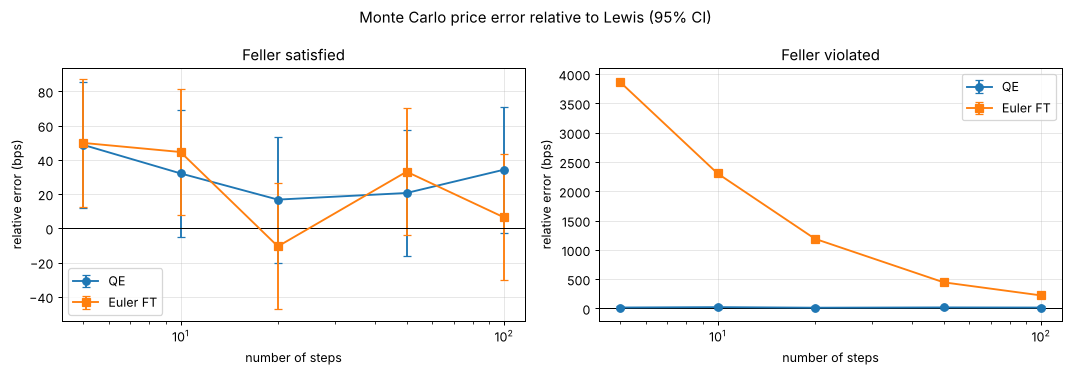

In [11]:
# FIG: biais_nsteps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (name, res) in zip(axes, bias_results.items()):
    ax.errorbar(res[:, 0], res[:, 1], yerr=res[:, 2], fmt="o-", capsize=3, label="QE")
    ax.errorbar(res[:, 0], res[:, 3], yerr=res[:, 4], fmt="s-", capsize=3, label="Euler FT")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("number of steps")
    ax.set_ylabel("relative error (bps)")
    ax.set_title(name)
    ax.legend()
fig.suptitle("Monte Carlo price error relative to Lewis (95% CI)")
plt.tight_layout()
plt.show()

## Test 3 — Statistical error

With the number of steps fixed ($n = 50$, QE scheme), we increase $N$. The half-width of the confidence interval should decrease as $N^{-1/2}$, and the realised error should remain inside this interval.

In [12]:
p = cases["Feller violated"]
ref = lewis_call_price(S0, K, T, r, **p)
S_all, _ = heston_paths_qe(S0, r, T, **p, n_steps=50, n_paths=1_000_000, seed=7)

N_list = np.array([1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000])
stat = []
for N in N_list:
    S_N = S_all[:N]
    c, se = mc_call_price(S_N, K, T, r)
    stat.append((N, c, se))
stat = np.array(stat)

print(f"{'N':>9} | {'MC price':>9} | {'95% CI':>8} | {'|MC - Lewis|':>12} | {'in the CI?':>11}")
for N, c, se in stat:
    inside = "yes" if abs(c - ref) <= 1.96 * se else "no"
    print(f"{int(N):9d} | {c:9.4f} | {1.96*se:8.4f} | {abs(c - ref):12.4f} | {inside:>11}")
print(f"\nLewis price = {ref:.4f}")
slope = np.polyfit(np.log(stat[:, 0]), np.log(stat[:, 2]), 1)[0]
print(f"Log-log slope of the standard error: {slope:.3f} (expected -0.5)")

        N |  MC price |   95% CI | |MC - Lewis| |  in the CI?
     1000 |    6.8424 |   0.4419 |       0.1798 |         yes
     3000 |    6.8025 |   0.2711 |       0.2197 |         yes
    10000 |    6.9807 |   0.1496 |       0.0416 |         yes
    30000 |    7.0728 |   0.0891 |       0.0506 |         yes
   100000 |    7.0777 |   0.0479 |       0.0555 |          no
   300000 |    7.0300 |   0.0275 |       0.0078 |         yes
  1000000 |    7.0195 |   0.0150 |       0.0028 |         yes

Lewis price = 7.0223
Log-log slope of the standard error: -0.492 (expected -0.5)


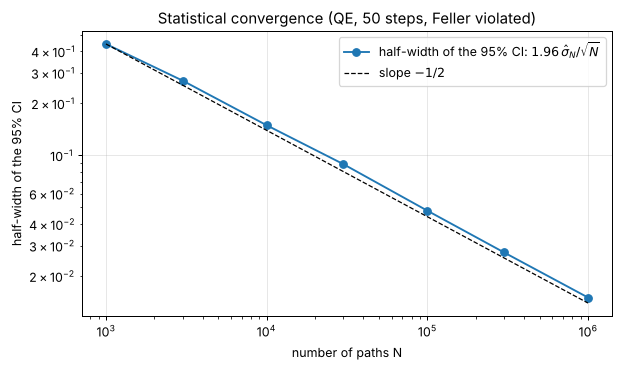

In [13]:
# FIG: convergence_N
half_width = 1.96 * stat[:, 2]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(stat[:, 0], half_width, "o-", label=r"half-width of the 95% CI: $1.96\,\hat\sigma_N/\sqrt{N}$")
ax.loglog(stat[:, 0], half_width[0] * np.sqrt(stat[0, 0] / stat[:, 0]), "k--", lw=1, label=r"slope $-1/2$")
ax.set_xlabel("number of paths N")
ax.set_ylabel("half-width of the 95% CI")
ax.set_title("Statistical convergence (QE, 50 steps, Feller violated)")
ax.legend()
plt.tight_layout()
plt.show()

## Test 4 — Computation time

In [14]:
timing = {}
for name, p in cases.items():
    t0 = time.perf_counter()
    heston_paths_qe(S0, r, T, **p, n_steps=100, n_paths=200_000, seed=1)
    t_qe = time.perf_counter() - t0
    t0 = time.perf_counter()
    heston_paths_euler(S0, r, T, **p, n_steps=100, n_paths=200_000, seed=1)
    t_eu = time.perf_counter() - t0
    timing[name] = (t_qe, t_eu)
    print(f"{name:16s} | QE : {t_qe:.2f} s | Euler FT : {t_eu:.2f} s | ratio QE/Euler = {t_qe/t_eu:.2f}")

t0 = time.perf_counter()
lewis_call_price(S0, K, T, r, **cases["Feller violated"])
print(f"\nFor comparison, one Lewis price: {(time.perf_counter() - t0)*1e3:.1f} ms")

Feller satisfied | QE : 2.38 s | Euler FT : 1.30 s | ratio QE/Euler = 1.83
Feller violated  | QE : 2.30 s | Euler FT : 1.16 s | ratio QE/Euler = 1.97

For comparison, one Lewis price: 3.1 ms


## Test 5 — Cross-check on a full smile

With the parameters where Feller is violated, we compare the implied volatility smile obtained by Monte Carlo (QE, 100 steps, $10^6$ paths) with that of the Lewis formula. The error bars reflect the confidence interval of the MC price, converted into implied volatility.

Maximum implied volatility gap: 3.5 bps


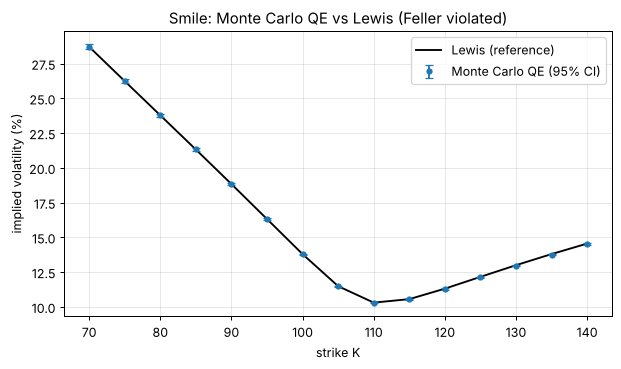

In [15]:
# FIG: smile_mc
p = cases["Feller violated"]
S_smile, _ = heston_paths_qe(S0, r, T, **p, n_steps=100, n_paths=1_000_000, seed=11)
K_grid = np.linspace(70, 140, 15)

iv_lewis, iv_mc, iv_lo, iv_hi = [], [], [], []
for Kk in K_grid:
    iv_lewis.append(implied_vol(lewis_call_price(S0, Kk, T, r, **p), S0, Kk, T, r))
    c, se = mc_call_price(S_smile, Kk, T, r)
    iv_mc.append(implied_vol(c, S0, Kk, T, r))
    iv_lo.append(implied_vol(c - 1.96 * se, S0, Kk, T, r))
    iv_hi.append(implied_vol(c + 1.96 * se, S0, Kk, T, r))
iv_lewis, iv_mc = np.array(iv_lewis), np.array(iv_mc)
err = np.vstack([iv_mc - np.array(iv_lo), np.array(iv_hi) - iv_mc])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(K_grid, iv_lewis * 100, "k-", label="Lewis (reference)")
ax.errorbar(K_grid, iv_mc * 100, yerr=err * 100, fmt="o", ms=4, capsize=3, label="Monte Carlo QE (95% CI)")
ax.set_xlabel("strike K")
ax.set_ylabel("implied volatility (%)")
ax.set_title("Smile: Monte Carlo QE vs Lewis (Feller violated)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Maximum implied volatility gap: {np.max(np.abs(iv_mc - iv_lewis))*1e4:.1f} bps")

# Part II — Variance reduction

With the scheme fixed, the statistical error is $1.96\,\sigma/\sqrt N$: halving it costs 4 times more paths. A variance reduction method replaces the simulated variable by another one **with the same expectation** and a lower variance. We compare three methods, built on the QE scheme, with standard Monte Carlo:

1. **Conditional**: we simulate only the variance; conditionally on its path, the price is a Black-Scholes price,
$$
Y^{\mathrm{cond}} = C_{\mathrm{BS}}(S_{\mathrm{eff}}, K, T, r, \sigma_{\mathrm{eff}}),\quad
S_{\mathrm{eff}} = S_0\exp\Big(\frac\rho\xi\big(v_T - v_0 - \kappa\theta T\big) + \frac{\kappa\rho}{\xi}I_T - \frac{\rho^2}{2}I_T\Big),\quad
\sigma_{\mathrm{eff}}^2 = \frac{(1-\rho^2)\,I_T}{T}.
$$
2. **Control variate**: on standard Monte Carlo, control $e^{-rT}S_T$, with expectation $S_0$.
3. **Conditional + control variate**: on the conditional estimator, control $S_{\mathrm{eff}}$, with expectation $S_0$.

In [16]:
def qe_variance_paths(T, kappa, theta, xi, v0, n_steps, n_paths, seed=0, psi_c=1.5):
    # Simulates only the variance (QE). Returns v_T and I_T (integral of v, trapezoidal rule).
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    v = np.full(n_paths, v0)
    I = np.zeros(n_paths)
    for _ in range(n_steps):
        Zv, U = rng.standard_normal(n_paths), rng.random(n_paths)
        v_next = qe_variance_from_draws(v, dt, kappa, theta, xi, Zv, U, psi_c)
        I = I + 0.5 * (v + v_next) * dt
        v = v_next
    return v, I


def conditional_bs_inputs(S0, T, kappa, theta, xi, rho, v0, v_T, I_T):
    S_eff = S0 * np.exp(rho / xi * (v_T - v0 - kappa * theta * T) + kappa * rho / xi * I_T - 0.5 * rho**2 * I_T)
    sigma_eff = np.sqrt((1 - rho**2) * I_T / T)
    return S_eff, sigma_eff

In [17]:
def mean_and_se(values):
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))


def with_control(Y, X, mean_X):
    # Single control variate: beta = Cov(Y, X) / Var(X), estimated on the sample.
    c = np.cov(Y, X)
    beta = c[0, 1] / c[1, 1]
    return Y - beta * (X - mean_X)


def payoff(S_T, K, T, r):
    return np.exp(-r * T) * np.maximum(S_T - K, 0.0)


METHODS = ["Standard", "Conditional", "Control variate", "Cond. + control"]


def simulate_all(p, n_steps, n_paths, seed):
    # One simulation per family of methods, reusable for all strikes. Also returns the times.
    sims, times = {}, {}
    t0 = time.perf_counter()
    sims["std"], _ = heston_paths_qe(S0, r, T, **p, n_steps=n_steps, n_paths=n_paths, seed=seed)
    times["std"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    v_T, I_T = qe_variance_paths(T, p["kappa"], p["theta"], p["xi"], p["v0"], n_steps, n_paths, seed=seed)
    sims["cond"] = conditional_bs_inputs(S0, T, p["kappa"], p["theta"], p["xi"], p["rho"], p["v0"], v_T, I_T)
    times["cond"] = time.perf_counter() - t0

    return sims, times


def estimate_all(sims, Kk):
    # Returns {method: (price, standard error)} for one strike.
    S_std, (S_eff, sig) = sims["std"], sims["cond"]
    Y_std = payoff(S_std, Kk, T, r)
    Y_cond = bs_call(S_eff, Kk, T, r, sig)
    return {
        "Standard": mean_and_se(Y_std),
        "Conditional": mean_and_se(Y_cond),
        "Control variate": mean_and_se(with_control(Y_std, np.exp(-r * T) * S_std, S0)),
        "Cond. + control": mean_and_se(with_control(Y_cond, S_eff, S0)),
    }


SIM_OF = {"Standard": "std", "Conditional": "cond", "Control variate": "std", "Cond. + control": "cond"}

## Test 6 — Comparison at the money

$N = 200\,000$ paths, $50$ steps, $K = 100$. For each method:

- the **variance gain** $\sigma^2_{\mathrm{std}}/\sigma^2_{\mathrm{method}}$, for the same number of paths;
- the **computation time** of the simulation; computing the estimators (means, regression, Black-Scholes formula) takes a few milliseconds;
- the **efficiency gain** $\dfrac{\sigma^2_{\mathrm{std}}\,t_{\mathrm{std}}}{\sigma^2_{\mathrm{method}}\,t_{\mathrm{method}}}$: the factor of time saved **for the same accuracy**.

In [18]:
N_vr, n_vr = 200_000, 50
vr_sims = {}
for name, p in cases.items():
    ref = lewis_call_price(S0, K, T, r, **p)
    sims, times = simulate_all(p, n_vr, N_vr, seed=3)
    vr_sims[name] = sims
    est = estimate_all(sims, K)
    se0, t0_ = est["Standard"][1], times["std"]
    print(f"\n--- {name} ---  Lewis price = {ref:.4f}")
    print(f"{'method':22s} | {'price':>8} | {'95% CI':>8} | {'gap to Lewis':>11} | {'var. gain':>9} | {'time (s)':>9} | {'effic. gain':>11}")
    for m in METHODS:
        c, se = est[m]
        t = times[SIM_OF[m]]
        g_var = (se0 / se)**2
        print(f"{m:22s} | {c:8.4f} | {1.96*se:8.4f} | {c - ref:+11.4f} | {g_var:8.1f}x | {t:9.2f} | {g_var * t0_ / t:10.1f}x")


--- Feller satisfied ---  Lewis price = 9.3081
method                 |    price |   95% CI | gap to Lewis | var. gain |  time (s) | effic. gain
Standard               |   9.2998 |   0.0542 |     -0.0083 |      1.0x |      1.13 |        1.0x
Conditional            |   9.3030 |   0.0251 |     -0.0051 |      4.7x |      0.94 |        5.6x
Control variate        |   9.2906 |   0.0254 |     -0.0174 |      4.5x |      1.13 |        4.5x
Cond. + control        |   9.3016 |   0.0082 |     -0.0065 |     43.5x |      0.94 |       52.4x

--- Feller violated ---  Lewis price = 7.0223
method                 |    price |   95% CI | gap to Lewis | var. gain |  time (s) | effic. gain
Standard               |   7.0073 |   0.0337 |     -0.0149 |      1.0x |      1.19 |        1.0x
Conditional            |   7.0243 |   0.0071 |     +0.0021 |     22.6x |      0.91 |       29.5x
Control variate        |   7.0181 |   0.0235 |     -0.0042 |      2.0x |      1.19 |        2.0x
Cond. + control        |   7.0

## Test 7 — Gain over the whole strike range, and absence of bias

We plot the variance gain of each method for $K$ from $70$ to $140$, in both cases, reusing the same simulation for all strikes. We also check, for each strike, that the gap to the Lewis price remains within the confidence interval.


--- Feller satisfied ---
method                 |  min gain |  max gain | max |gap to Lewis| / CI
Conditional            |      3.0x |     79.8x |                   0.38
Control variate        |      1.1x |     79.0x |                   0.37
Cond. + control        |     40.0x |    438.0x |                   0.26

--- Feller violated ---
method                 |  min gain |  max gain | max |gap to Lewis| / CI
Conditional            |      3.2x |     40.3x |                   0.46
Control variate        |      1.1x |     10.2x |                   0.62
Cond. + control        |     15.7x |     55.7x |                   0.48


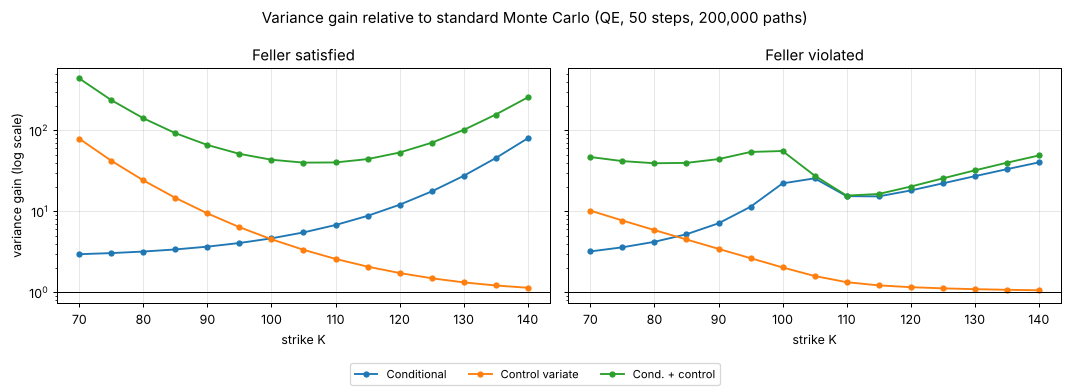

In [19]:
# FIG: gain_variance_strikes
K_list = np.linspace(70, 140, 15)
methods_vr = METHODS[1:]
strike_gains, max_z = {}, {}
for name, p in cases.items():
    sims, _ = simulate_all(p, n_vr, N_vr, seed=5)
    g = {m: [] for m in methods_vr}
    z = {m: 0.0 for m in methods_vr}
    for Kk in K_list:
        ref_k = lewis_call_price(S0, Kk, T, r, **p)
        est = estimate_all(sims, Kk)
        se0 = est["Standard"][1]
        for m in methods_vr:
            c, se = est[m]
            g[m].append((se0 / se)**2)
            z[m] = max(z[m], abs(c - ref_k) / (1.96 * se))
    strike_gains[name], max_z[name] = g, z

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, (name, g) in zip(axes, strike_gains.items()):
    for m in methods_vr:
        ax.semilogy(K_list, g[m], "o-", ms=4, label=m)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_xlabel("strike K")
    ax.set_title(name)
axes[0].set_ylabel("variance gain (log scale)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Variance gain relative to standard Monte Carlo (QE, 50 steps, 200,000 paths)")
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

for name in cases:
    print(f"\n--- {name} ---")
    print(f"{'method':22s} | {'min gain':>9} | {'max gain':>9} | {'max |gap to Lewis| / CI':>22}")
    for m in methods_vr:
        print(f"{m:22s} | {min(strike_gains[name][m]):8.1f}x | {max(strike_gains[name][m]):8.1f}x | {max_z[name][m]:22.2f}")